# Example metrics reporting: Town Neck Beach

This notebook reports saved RGB-only transfer-learning experiments; it does not train models, change predictions, or modify the manuscript. It contains two reports:
1. Mean validation macro-F1 and sample standard deviation over the four grid-search configurations for each backbone and context radius. These are different hyperparameter configurations, not repeated random seeds or uncertainty estimates. Test F1 is unavailable for non-winning grid configurations.
2. Aggregated test-set metrics for five validation-selected backbones and all four ensemble methods, followed by LaTeX matching the manuscript's Table VI style. Accuracy, macro precision, macro recall, macro-F1, and MCC are recomputed from predictions. Best unrounded values are shaded in grey.

All methods use the same 1,493 spatially held-out test targets. Ensemble weights and the preferred ensemble method are fitted/selected on validation, never on test. Comparing test scores here is descriptive; it does not change the saved validation selection. Dense source labels originate from human-guided segmentation. Rare classes have few held-out targets, so high overall accuracy need not imply strong minority-class performance.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Source').is_dir() and (p / 'Notebooks').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.bs_town_neck_reporting import (
    BACKBONES, ENSEMBLES, METRICS, load_town_neck_report, plot_context_f1, aggregate_latex
)

# Optional PDF export. Set a directory explicitly; None means notebook display only.
FIGURE_DIR = PROJECT_ROOT.parent / 'manuscript' / 'fig'

get_ipython().run_line_magic('matplotlib', 'inline')
print('Results:', PROJECT_ROOT / 'Results', flush=True)

/Users/piotr/Praca/Nauka/publikacje/Context_Aware_Deep_Learning_Beach_Classification/software/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Results: /Users/piotr/Praca/Nauka/publikacje/Context_Aware_Deep_Learning_Beach_Classification/software/Results


In [2]:
metrics, context_summary, validation_selected_ensemble = load_town_neck_report(PROJECT_ROOT)
print('Verified all 80 grid-search runs: four combinations per radius and backbone.', flush=True)
print('Verified split provenance, validation-selected configurations, model metadata, and test-row alignment.', flush=True)
print('Recomputed all nine methods and reproduced all four ensemble predictions from component probabilities.', flush=True)
print('Validation-selected ensemble:', ENSEMBLES[validation_selected_ensemble], flush=True)

Verified all 80 grid-search runs: four combinations per radius and backbone.


Verified split provenance, validation-selected configurations, model metadata, and test-row alignment.


Recomputed all nine methods and reproduced all four ensemble predictions from component probabilities.


Validation-selected ensemble: Hard voting


## 1. Context-radius comparison

Each bar is the mean **validation macro-F1** across the four learning-rate/weight-decay configurations at that radius; error bars are sample SD (ddof = 1). Dropout follows the original architecture-specific grid. SD describes variation across configurations, not independent replications. A model's best mean radius can differ from the radius of its single best validation configuration.

,r = 0,r = 1,r = 2,r = 3
Method,,,,
Small CNN,0.610 +/- 0.012,0.665 +/- 0.019,0.638 +/- 0.013,0.642 +/- 0.022
EfficientNetV2-S,0.671 +/- 0.024,0.697 +/- 0.040,0.742 +/- 0.015,0.759 +/- 0.051
ViT-Tiny,0.674 +/- 0.036,0.711 +/- 0.026,0.763 +/- 0.029,0.743 +/- 0.050
Swin-Tiny,0.648 +/- 0.034,0.751 +/- 0.038,0.786 +/- 0.019,0.745 +/- 0.056
ConvNeXt-Tiny,0.677 +/- 0.061,0.725 +/- 0.035,0.735 +/- 0.050,0.760 +/- 0.051


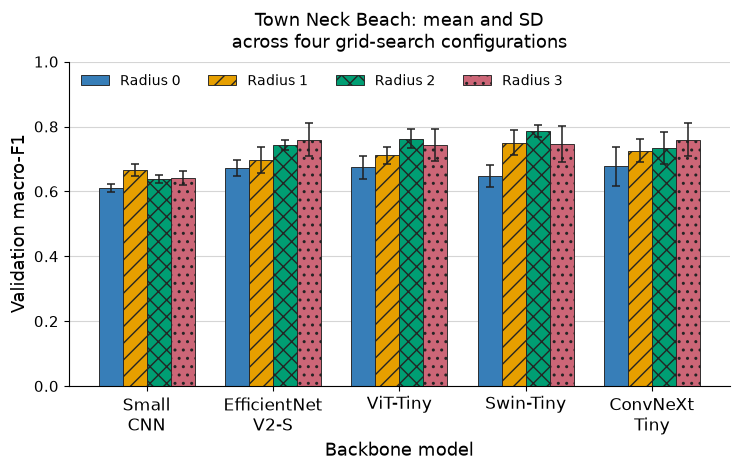

Small CNN: highest mean validation macro-F1 at r=1 (0.665 +/- 0.019)
EfficientNetV2-S: highest mean validation macro-F1 at r=3 (0.759 +/- 0.051)
ViT-Tiny: highest mean validation macro-F1 at r=2 (0.763 +/- 0.029)
Swin-Tiny: highest mean validation macro-F1 at r=2 (0.786 +/- 0.019)
ConvNeXt-Tiny: highest mean validation macro-F1 at r=3 (0.760 +/- 0.051)


In [3]:
context_display = context_summary.copy()
context_display['Mean +/- SD'] = context_display.apply(lambda row: f"{row['mean']:.3f} +/- {row['sd']:.3f}", axis=1)
context_table = context_display.pivot(index='Method', columns='context_radius', values='Mean +/- SD').reindex(BACKBONES.values())
context_table.columns = [f'r = {r}' for r in context_table.columns]
display(context_table)
context_figure = plot_context_f1(context_summary)
if FIGURE_DIR is not None:
    output = Path(FIGURE_DIR).expanduser()
    if not output.is_absolute():
        output = PROJECT_ROOT / output
    output.mkdir(parents=True, exist_ok=True)
    context_figure.savefig(output / 'town_neck_backbones_context_f1.pdf', bbox_inches='tight')
plt.show()
for model, label in BACKBONES.items():
    group = context_summary.loc[context_summary.model.eq(model)]
    best = group.loc[group['mean'].idxmax()]
    print(f"{label}: highest mean validation macro-F1 at r={int(best.context_radius)} ({best['mean']:.3f} +/- {best.sd:.3f})")

## 2. Overall test performance and LaTeX

Each backbone row uses its **single validation-selected** configuration, not its mean grid-search score. All ensemble rows use the same four advanced backbone artifacts; Small CNN is excluded from ensembles. Radius vectors follow EfficientNetV2-S, ViT-Tiny, Swin-Tiny, ConvNeXt-Tiny.

The LaTeX uses a one-column table, bold abbreviated headers, horizontal separators, multiline method/context labels, and grey highlighting based on unrounded metric values. It requires `\usepackage[table]{xcolor}` for `\cellcolor`. Values are displayed to three decimal places; apparent rounded ties may not be exact ties.

In [4]:
display(metrics[['Method', 'Context', *METRICS]].style.format({key: '{:.3f}' for key in METRICS}).highlight_max(subset=METRICS, color='#e6e6e6'))
best_f1 = metrics.loc[metrics.macro_f1.idxmax()]
print(f"Highest observed test macro-F1: {best_f1['Method']} ({best_f1.macro_f1:.3f}).")
print('The validation-selected ensemble remains', ENSEMBLES[validation_selected_ensemble] + '; test ranking does not alter selection.')
print('\nLaTeX table:\n')
print(aggregate_latex(metrics))

,Method,Context,accuracy,macro_precision,macro_recall,macro_f1,mcc
0,Small CNN,1,0.919,0.664,0.728,0.689,0.877
1,EfficientNetV2-S,3,0.946,0.793,0.760,0.770,0.917
2,ViT-Tiny,3,0.952,0.827,0.759,0.782,0.926
3,Swin-Tiny,2,0.950,0.737,0.831,0.761,0.922
4,ConvNeXt-Tiny,3,0.962,0.831,0.756,0.774,0.941
5,Hard voting,"(3,3,2,3)",0.963,0.822,0.758,0.778,0.943
6,Probability voting,"(3,3,2,3)",0.963,0.815,0.750,0.772,0.943
7,Globally weighted probability voting,"(3,3,2,3)",0.963,0.815,0.750,0.772,0.943
8,Model-and-class weighted probability voting,"(3,3,2,3)",0.963,0.815,0.750,0.772,0.943


Highest observed test macro-F1: ViT-Tiny (0.782).
The validation-selected ensemble remains Hard voting; test ranking does not alter selection.

LaTeX table:

\begin{table}[!t]
\caption{Aggregated test-set metrics for Town Neck Beach after fine-tuning the RGB-only Svalbard models. Each backbone uses its validation-selected configuration. Precision, recall, and F1-score are macro averages over six classes. Ensemble radius vectors follow EfficientNetV2-S, ViT-Tiny, Swin-Tiny, and ConvNeXt-Tiny. The best unrounded values are shaded in grey.}
\label{tab:town-neck-aggregate-metrics}
\centering
\footnotesize
\setlength{\tabcolsep}{4.0pt}
\renewcommand{\arraystretch}{1.05}
\begin{tabular}{lrrrrr}
\hline
\textbf{Method} & \textbf{Acc.} & \textbf{Prec.} & \textbf{Rec.} & \textbf{F1-score} & \textbf{MCC} \\
\hline
\shortstack[l]{Small CNN\\RGB only; $r=1$} & 0.919 & 0.664 & 0.728 & 0.689 & 0.877 \\
\hline
\shortstack[l]{EfficientNetV2-S\\RGB only; $r=3$} & 0.946 & 0.793 & 0.760 & 0.770 & 0.917 \\